## Mengapa Menggunakan Scikit-learn?
Scikit-learn adalah salah satu library paling populer untuk machine learning di Python karena beberapa alasan:

- **Sederhana**: API-nya intuitif dengan sintaks yang konsisten (fit, predict, transform).
- **Komprehensif**: Mendukung berbagai algoritma untuk klasifikasi, regresi, pengelompokan, dan reduksi dimensi.
- **Integrasi**: Bekerja mulus dengan library lain seperti NumPy, pandas, dan Matplotlib.
- **Ekstensibilitas**: Menyediakan alat untuk pra-pemrosesan data, evaluasi model, dan penyetelan hyperparameter.
- **Dukungan Komunitas**: Didukung oleh komunitas open-source aktif dengan dokumentasi dan tutorial yang ekstensif.

In [3]:
import sklearn
print(sklearn.__version__)

1.9.0


## **Studi Kasus: Dataset Harga Rumah California** <br>
**Tujuan**: Jelajahi harga rumah dan identifikasi prediktor potensial seperti pendapatan median dan populasi.

In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv(r'E:\DigitalentDA\Datasets\dataset6.csv')
df = pd.DataFrame(data)

print(df.head())
print(df.info())
print(df.describe())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                  41          880           129.0   
1    -122.22     37.86                  21         7099          1106.0   
2    -122.24     37.85                  52         1467           190.0   
3    -122.25     37.85                  52         1274           235.0   
4    -122.25     37.85                  52         1627           280.0   

   population  households  median_income ocean_proximity  median_house_value  
0         322         126         8.3252        NEAR BAY              452600  
1        2401        1138         8.3014        NEAR BAY              358500  
2         496         177         7.2574        NEAR BAY              352100  
3         558         219         5.6431        NEAR BAY              341300  
4         565         259         3.8462        NEAR BAY              342200  
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data colum

In [142]:
# Sebelum handle missing values
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
median_house_value      0
dtype: int64


In [143]:
# Handle missing values dengan median
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [144]:
# Setelah handle missing values
print(df.isnull().sum())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
median_house_value    0
dtype: int64


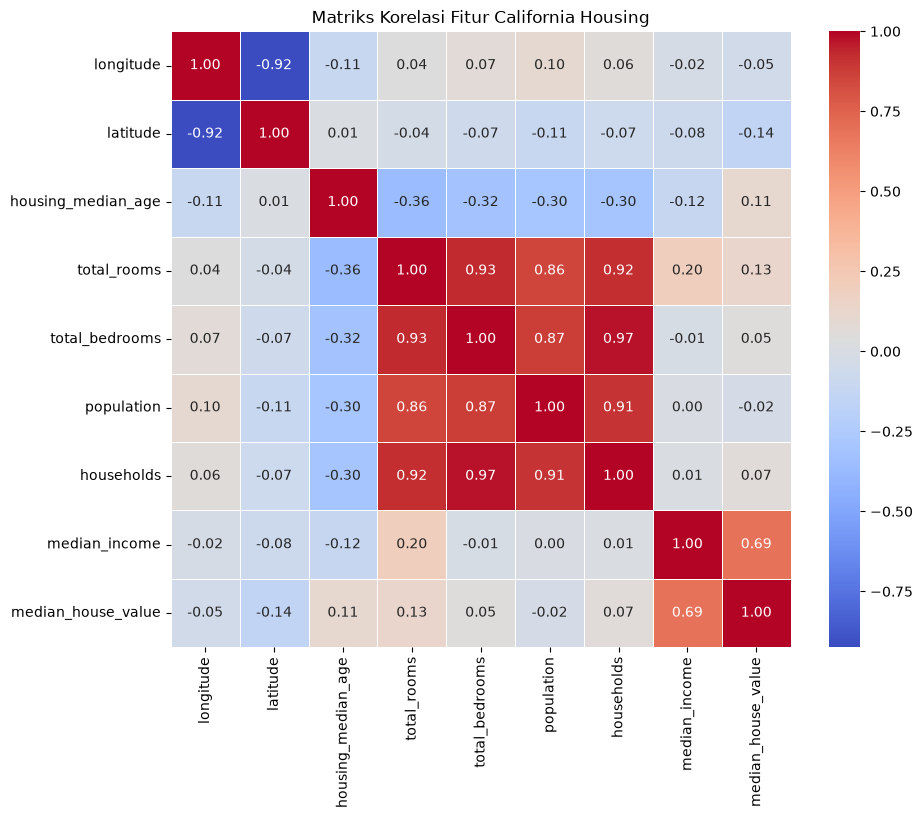

In [145]:
# Menghitung matriks korelasi untuk kolom numerik
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
# print(corr_matrix)

# Membuat heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths='0.5')
plt.title("Matriks Korelasi Fitur California Housing")
plt.show()

Impact antara median_income dengan median_house_value = 0.68 <br>
Semakin kaya penduduk (median_income++), semakin mahal harga rumah (media_house_value++)

In [ ]:
# Feature Engineering
df['rooms_per_households'] = df['total_rooms'] / df['households']
df['population_per_households'] = df['population'] / df['households']

df_clean = df.drop(columns=['ocean_proximity'])

In [174]:
# Split fitur X dan target y
X = data[['median_income']]
y = data['median_house_value']

In [175]:
# Data di split untuk data training dan data testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data latihan: {X_train.shape[0]}")
print(f"Jumlah data pengujian: {X_test.shape[0]}")

Jumlah data latihan: 16512
Jumlah data pengujian: 4128


In [176]:
# Latih data dengan model Regresi Linear
from sklearn.linear_model import LinearRegression
# Evaluasi model
from sklearn.metrics import mean_squared_error, r2_score

# Insialisasi
model = LinearRegression()
# Latih model 
model.fit(X_train, y_train)
# Prediksi dengan data testing
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)

print(f"Mean Squared Error: {mse}")

Mean Squared Error: 7091157771.76555


In [177]:
# Persamaan Matematika Model
intercept = model.intercept_
slope = model.coef_[0]

print("--- Hasil Rumus Model ---")
print(f"Intercept (Beta 0): {intercept:.2f}")
print(f"Slope/Koefisien (Beta 1): {slope:.2f}")
print(f"\nPersamaan: Harga Rumah = {intercept:.2f} + ({slope:.2f} * Median Income)")

--- Hasil Rumus Model ---
Intercept (Beta 0): 44459.73
Slope/Koefisien (Beta 1): 41933.85

Persamaan: Harga Rumah = 44459.73 + (41933.85 * Median Income)


- Intercept ($\beta_0$): Secara teori, jika pendapatan warganya adalah $0$, maka harga dasar rumah di sana berkisar di angka intercept tersebut.
- Slope ($\beta_1$): Setiap kenaikan $1$ unit nilai pendapatan (median_income), maka harga rumah diprediksi akan naik sebesar nilai slope tersebut (bernilai positif, artinya hubungan mereka searah).

In [178]:
# Evaluasi Performa Model
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("--- Evaluasi Model ---")
print(f"R-squared Score: {r2:.4f}")
print(f"RMSE: ${rmse:.2f}")

--- Evaluasi Model ---
R-squared Score: 0.4589
RMSE: $84209.01


RMSE adalah metrik yang mengukur rata-rata jarak (selisih) antara angka yang diprediksi oleh model dengan angka asli di data lapangan.

Fungsi utamanya adalah memberi tahu kita: "Rata-rata, tebakan model kita itu meleset seberapa jauh sih?" Hebatnya, RMSE memiliki satuan yang sama persis dengan variabel target kita. Jika kita memprediksi harga rumah dalam satuan Dolar ($), nilai RMSE yang keluar juga berwujud Dolar. Ini membuatnya sangat mudah diinterpretasikan oleh manusia.

Jika RMSE mengukur jarak melesetnya tebakan, $R^2$ mengukur seberapa pintar model kita dibandingkan dengan model tebakan paling malas di dunia. Model paling malas itu adalah model yang selalu menebak harga rumah menggunakan nilai rata-rata (mean) dari seluruh harga rumah tanpa melihat fitur apa pun.

$R^2$ biasanya bernilai antara 0 sampai 1 (atau 0% hingga 100%). Nilai $R^2$ sebesar 0.48 berarti kolom median_income mampu menjelaskan 48% variasi naik-turunnya harga rumah di California, sementara 52% sisanya disebabkan oleh faktor lain yang belum dimasukkan ke model (seperti lokasi atau ukuran).

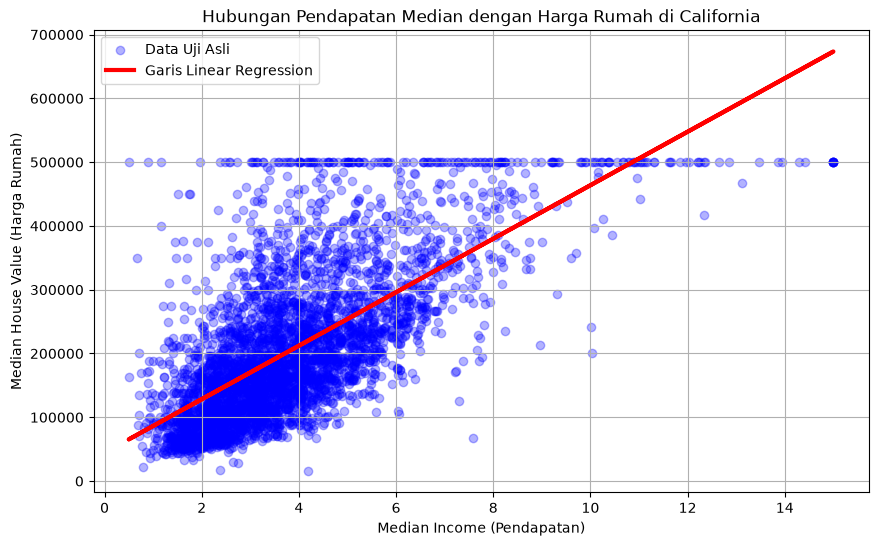

In [179]:
# Visualisasi Regresi
plt.figure(figsize=(10, 6))

# Gambar titik-titik data uji asli (Scatter Plot)
plt.scatter(X_test, y_test, color='blue', alpha=0.3, label='Data Uji Asli')

# Gambar garis prediksi model (Line Plot)
plt.plot(X_test, y_pred, color='red', linewidth=3, label='Garis Linear Regression')

plt.title('Hubungan Pendapatan Median dengan Harga Rumah di California')
plt.xlabel('Median Income (Pendapatan)')
plt.ylabel('Median House Value (Harga Rumah)')
plt.legend()
plt.grid(True)
plt.show()

In [180]:
# Melihat nilai asli, nilai prediksi, dan error
df_compare = pd.DataFrame({
    'Nilai Asli (y_test)': y_test.values,
    'Nilai Prediksi (y_pred)': y_pred,
    'Error': abs(y_test.values - y_pred)
})

# print(df_compare.head(10))
print(df_compare.sample(10, random_state=1))
print(df_compare['Error'].describe())

      Nilai Asli (y_test)  Nilai Prediksi (y_pred)          Error
123                208800            114740.860753   94059.139247
3455               335000            250053.005977   84946.994023
416                500001            214036.022733  285964.977267
2084                64900            124318.551955   59418.551955
718                376600            281021.153754   95578.846246
1373               107100            180744.739699   73644.739699
17                 187500            217839.422873   30339.422873
3705               234200            234558.448626     358.448626
2343               262500            186263.234279   76236.765721
644                331800            223429.204997  108370.795003
count      4128.000000
mean      62990.865301
std       55893.340026
min          19.689867
25%       25463.814729
50%       50190.783901
75%       82176.219784
max      434578.539519
Name: Error, dtype: float64
